# Studiul de caz 3 - Acțiunile companiilor energetice românești, petrolul și gazele: corelația variabilă în timp și acoperirea riscului

Energy MBA - Analiza cantitativă a piețelor de energie (EMQA) - Prof. Daniel Traian Pele

Academia de Studii Economice din București - Academia Română, Institutul de Prognoză Economică

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "ro"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Lucrarea de referință.** Grecu, R. A., Cramer, A. A., Pele, D. T. și Lessmann, S. (2025). The link between energy prices and stock markets in European Union
countries. *The North American Journal of Economics and Finance*, 78, 102420. doi:10.1016/j.najef.2025.102420

**Conținutul notebook-ului.** Lucrarea estimează un model DCC-GARCH (corelație condiționată dinamică, cu heteroscedasticitate condiționată autoregresivă
generalizată) între 27 de indici bursieri din UE și prețurile Brent / TTF, apoi un model Markov cu două regimuri pe corelația obținută.
Aplicăm cei doi pași acțiunilor companiilor *energetice* românești listate la București - OMV Petrom (SNP), Romgaz (SNG), Nuclearelectrica (SNN) - în raport cu Brent
și folosim corelația estimată pentru o decizie de acoperire a riscului.

**Adaptarea pentru curs.** Lucrarea folosește *indici* bursieri (inclusiv indicele BET) și contracte futures generice zilnice pe Brent și TTF, 2010-2023.
Noi folosim trei *companii* energetice, 2015-2026; seria zilnică TTF nu este disponibilă gratuit, de aceea analiza pentru gaze folosește prețul TTF lunar (Banca Mondială).

## 1. Datele și randamentele

In [2]:
eq = cu.equities_daily()
fu = cu.fuels_daily()
px = pd.concat({"SNP": eq["SNP_adjclose_ron"], "SNG": eq["SNG_adjclose_ron"], "SNN": eq["SNN_adjclose_ron"],
                "Brent": fu["brent_usd_bbl"] / fu["eurusd_ecb"]}, axis=1)        # Brent converted to EUR/bbl
vol = eq[["SNP_volume", "SNG_volume", "SNN_volume"]].sum(axis=1)
px = px[px.index.isin(vol[vol > 0].index)].dropna()                                 # trading days with prices for all four (BVB and ICE both open)
px = px.loc["2015-01-01":]
r = 100 * np.log(px).diff().dropna()                         # daily log returns, %
r["Basket"] = r[["SNP", "SNG", "SNN"]].mean(axis=1)          # equal-weight Romanian energy basket
print(r.shape, r.index.min().date(), r.index.max().date())
print(r.describe().T[["mean", "std", "min", "max"]].round(3))

(2860, 5) 2015-01-06 2026-11-04
         mean    std     min     max
SNP     0.079  1.501 -14.978   9.992
SNG     0.093  1.396 -11.035   9.131
SNN     0.112  1.514  -9.421  11.251
Brent   0.022  2.745 -35.940  19.352
Basket  0.095  1.141  -9.914   6.333


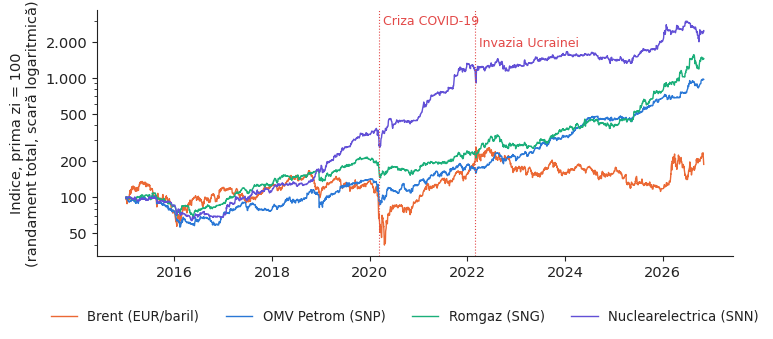

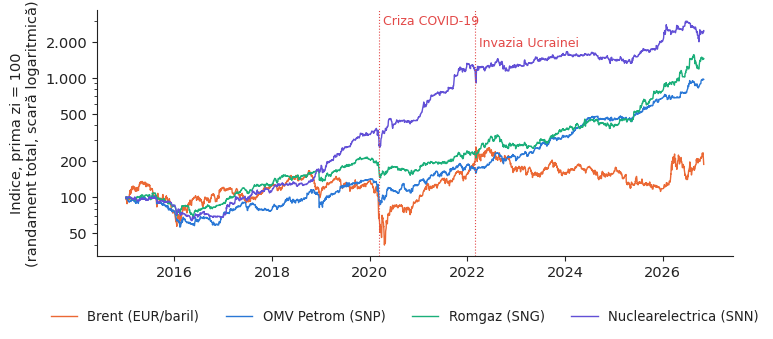

In [3]:
EVENTS = [("2020-03-09", ("COVID-19 crash", "Criza COVID-19")), ("2022-02-24", ("Invasion of Ukraine", "Invazia Ucrainei")),
          ("2022-09-01", ("Windfall tax, price caps (RO)", "Impozit pe veniturile suplimentare, plafonarea prețurilor (RO)"))]
def fig_prices(lang):
    fig, ax = plt.subplots(figsize=(8.2, 3.2))
    norm = 100 * px / px.iloc[0]
    cols = {"SNP": cu.PAL["RO"], "SNG": cu.PAL["HU"], "SNN": cu.PAL["c7"], "Brent": cu.PAL["DE_LU"]}
    labs = {"SNP": "OMV Petrom (SNP)", "SNG": "Romgaz (SNG)", "SNN": "Nuclearelectrica (SNN)", "Brent": cu.T(lang, "Brent (EUR/bbl)", "Brent (EUR/baril)")}
    for c in ["Brent", "SNP", "SNG", "SNN"]:
        ax.plot(norm.index, norm[c], color=cols[c], lw=1.0, label=labs[c])
    import matplotlib.transforms as mtrans
    for i_, (d, l) in enumerate(EVENTS[:2]):            # staggered so that the two labels never overlap
        ax.axvline(pd.Timestamp(d), color=cu.EVENT, lw=0.8, ls=":")
        ax.text(pd.Timestamp(d), 0.98 - 0.09 * i_, " " + cu.T(lang, *l), color=cu.EVENT, fontsize=9, va="top",
                transform=mtrans.blended_transform_factory(ax.transData, ax.transAxes))
    ax.set_ylabel(cu.T(lang, "Index, first day = 100\n(total return, log scale)", "Indice, prima zi = 100\n(randament total, scară logaritmică)"))
    ax.set_yscale("log")
    from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
    ax.yaxis.set_major_locator(FixedLocator([50, 100, 200, 500, 1000, 2000, 5000]))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _p: f"{v:,.0f}".replace(",", "." if lang == "ro" else ",")))
    ax.yaxis.set_minor_formatter(NullFormatter())
    cu.legend_bottom(fig, ncol=4)
    return fig
cu.save_both(fig_prices, "f1_prices")

## 2. Pasul 1 - DCC-GARCH: o corelație care se modifică de la o zi la alta

In [4]:
from arch import arch_model
from scipy.optimize import minimize

def garch_std(x):
    """GARCH(1,1) with Student-t errors; returns standardised residuals and conditional volatility."""
    m = arch_model(x, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
    return m.std_resid, m.conditional_volatility, m

def dcc_path(z, a, b, Qbar):
    """DCC(1,1) filter with given (a, b, Qbar): R_t uses z_1..z_{t-1} only (a one-step-ahead correlation forecast)."""
    z = np.asarray(z); T, k = z.shape
    Q = Qbar.copy(); R = np.empty((T, k, k))
    for t in range(T):
        d = np.sqrt(np.diag(Q)); R[t] = Q / np.outer(d, d)
        Q = (1 - a - b) * Qbar + a * np.outer(z[t], z[t]) + b * Q
    return R

def dcc(z):
    """Two-step DCC(1,1) of Engle (2002) on standardised residuals z (T x k). Returns a, b, the correlation path R_t and Qbar."""
    z = np.asarray(z); T, k = z.shape
    Qbar = np.cov(z.T)
    def path(a, b):
        Q = Qbar.copy(); R = np.empty((T, k, k)); ll = 0.0
        for t in range(T):
            d = np.sqrt(np.diag(Q)); Rt = Q / np.outer(d, d); R[t] = Rt
            zt = z[t]
            ll += np.log(np.linalg.det(Rt)) + zt @ np.linalg.solve(Rt, zt)
            Q = (1 - a - b) * Qbar + a * np.outer(zt, zt) + b * Q
        return ll, R
    obj = lambda p: path(p[0], p[1])[0] if (p[0] > 0 and p[1] > 0 and p[0] + p[1] < 0.999) else 1e12
    opt = minimize(obj, x0=[0.03, 0.95], method="Nelder-Mead", options={"xatol": 1e-5, "fatol": 1e-3})
    a, b = opt.x
    return a, b, path(a, b)[1], Qbar

std, vol_c, fits = {}, {}, {}
for c in ["SNP", "SNG", "SNN", "Basket", "Brent"]:
    std[c], vol_c[c], fits[c] = garch_std(r[c])
rho, dcc_par = {}, {}
for c in ["SNP", "SNG", "SNN", "Basket"]:
    a, b, R, _ = dcc(pd.concat([std[c], std["Brent"]], axis=1).values)
    rho[c] = pd.Series(R[:, 0, 1], index=r.index); dcc_par[c] = (a, b)
    print(f"{c}: DCC a = {a:.4f}, b = {b:.4f}, mean correlation with Brent = {rho[c].mean():.3f}")
rho = pd.DataFrame(rho)

SNP: DCC a = 0.0113, b = 0.9648, mean correlation with Brent = 0.112


SNG: DCC a = 0.0120, b = 0.9667, mean correlation with Brent = 0.104


SNN: DCC a = 0.0246, b = 0.9146, mean correlation with Brent = 0.080


Basket: DCC a = 0.0210, b = 0.9496, mean correlation with Brent = 0.126


## 3. Pasul 2 - Modelul Markov: regimuri de corelație ridicată și scăzută

In [5]:
import statsmodels.api as sm
ms = {}
for c in ["Basket", "SNP", "SNG", "SNN"]:
    mod = sm.tsa.MarkovRegression(rho[c].values, k_regimes=2, trend="c", switching_variance=True)
    np.random.seed(2026)                     # fixed seed: the random start values make the fit reproducible
    res_ms = mod.fit(disp=False, search_reps=10)
    pn = list(res_ms.model.param_names); const = np.array([res_ms.params[pn.index(f"const[{i}]")] for i in range(2)])
    hi = int(np.argmax(const)); lo = 1 - hi
    P = res_ms.regime_transition                         # P[i, j] = Pr(s_t = i | s_{t-1} = j)
    ms[c] = {"const_high": const[hi], "const_low": const[lo], "p_stay_high": P[hi, hi, 0], "p_stay_low": P[lo, lo, 0],
             "share_high": 100 * (res_ms.smoothed_marginal_probabilities[:, hi] > 0.5).mean(),
             "prob_high": pd.Series(res_ms.smoothed_marginal_probabilities[:, hi], index=rho.index)}
tab_ms = pd.DataFrame({c: {k: v for k, v in d.items() if k != "prob_high"} for c, d in ms.items()}).T
cu.show_table(tab_ms, digits=3)

,const_high,const_low,p_stay_high,p_stay_low,share_high
Basket,0.187,0.050,0.986,0.982,55.070
SNP,0.158,0.079,0.983,0.988,41.259
SNG,0.146,0.079,0.983,0.990,37.378
SNN,0.081,0.077,0.976,0.946,69.685


In [6]:
yr = rho.groupby(rho.index.year)
summary = pd.DataFrame({c: {"mean": rho[c].mean(), "max": rho[c].max(), "year_max": rho[c].idxmax().year,
                            "min": rho[c].min(), "year_min": rho[c].idxmin().year} for c in rho.columns}).T
summary = summary.join(tab_ms[["const_high", "const_low", "p_stay_high", "p_stay_low"]])
print(summary.round(3))
names = {"Basket": ("RO energy basket", "Coșul energetic RO"), "SNP": ("OMV Petrom (SNP)", "OMV Petrom (SNP)"),
         "SNG": ("Romgaz (SNG)", "Romgaz (SNG)"), "SNN": ("Nuclearelectrica (SNN)", "Nuclearelectrica (SNN)")}
t = summary.copy(); t.index = [names[i] for i in t.index]
t["year_max"] = t["year_max"].astype(int).astype(str); t["year_min"] = t["year_min"].astype(int).astype(str)
cu.write_table(t, "dcc", header=[("Series vs Brent", "Serie față de Brent"), ("Mean", "Media"), ("Max", "Max"), ("Year", "Anul"), ("Min", "Min"), ("Year", "Anul"),
                                 ("High regime", "Regim ridicat"), ("Low regime", "Regim scăzut"), ("$p_{HH}$", "$p_{HH}$"), ("$p_{LL}$", "$p_{LL}$")],
               digits={"mean": 2, "max": 2, "min": 2, "const_high": 3, "const_low": 3, "p_stay_high": 4, "p_stay_low": 4},
               best={"mean": "max", "p_stay_high": "max"})

         mean    max  year_max    min  year_min  const_high  const_low  p_stay_high  p_stay_low
SNP     0.112  0.421    2020.0 -0.087    2022.0       0.158      0.079        0.983       0.988
SNG     0.104  0.429    2015.0 -0.108    2022.0       0.146      0.079        0.983       0.990
SNN     0.080  0.489    2020.0 -0.323    2022.0       0.081      0.077        0.976       0.946
Basket  0.126  0.536    2020.0 -0.315    2022.0       0.187      0.050        0.986       0.982


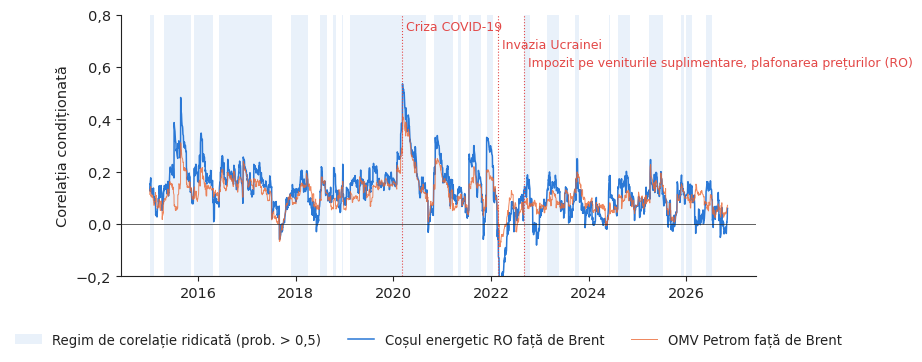

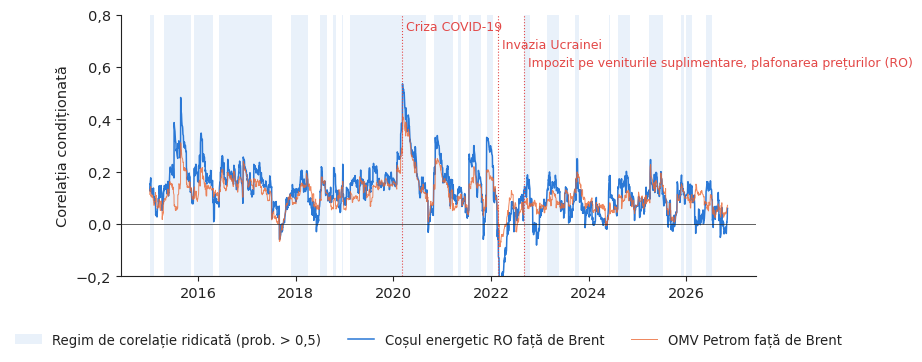

In [7]:
def fig_dcc(lang):
    fig, ax = plt.subplots(figsize=(8.2, 3.4))
    p = ms["Basket"]["prob_high"]
    ax.fill_between(p.index, -0.2, 0.8, where=p > 0.5, color=cu.PAL["RO"], alpha=0.10, lw=0,
                    label=cu.T(lang, "High-correlation regime (prob. > 0.5)", "Regim de corelație ridicată (prob. > 0,5)"))
    ax.plot(rho.index, rho["Basket"], color=cu.PAL["RO"], lw=1.1, label=cu.T(lang, "RO energy basket vs Brent", "Coșul energetic RO față de Brent"))
    ax.plot(rho.index, rho["SNP"], color=cu.PAL["DE_LU"], lw=0.7, alpha=0.8, label=cu.T(lang, "OMV Petrom vs Brent", "OMV Petrom față de Brent"))
    for (d, l), yy_ in zip(EVENTS, [0.78, 0.71, 0.64]):
        ax.axvline(pd.Timestamp(d), color=cu.EVENT, lw=0.8, ls=":")
        ax.text(pd.Timestamp(d), yy_, " " + cu.T(lang, *l), color=cu.EVENT, fontsize=9, va="top", rotation=0)
    ax.axhline(0, color=cu.INK, lw=0.5)
    ax.set_ylim(-0.2, 0.8)
    ax.set_ylabel(cu.T(lang, "Conditional correlation", "Corelația condiționată"))
    cu.comma_axis(ax, lang, "y", 1)
    cu.legend_bottom(fig, ncol=3)
    return fig
cu.save_both(fig_dcc, "f2_dcc_correlation", headline=True)

**Interpretarea graficului.** Corelația este departe de a fi constantă: crește brusc în perioadele de criză și rămîne ani la rînd într-un regim „ridicat” sau „scăzut”.
Lucrarea identifică aceleași două trăsături pentru indicii din UE: salturi la începutul anului 2020 și puncte de inflexiune în 2022 (secțiunea 4.1, Tabelul 2), precum și o
probabilitate de a rămîne în același regim de peste 98 % (Tabelul 4).

## 4. Gazele naturale: corelația lunară cu TTF

       Basket    SNP    SNG    SNN
Brent   0.281  0.389  0.284  0.022
TTF     0.089  0.086  0.096  0.038


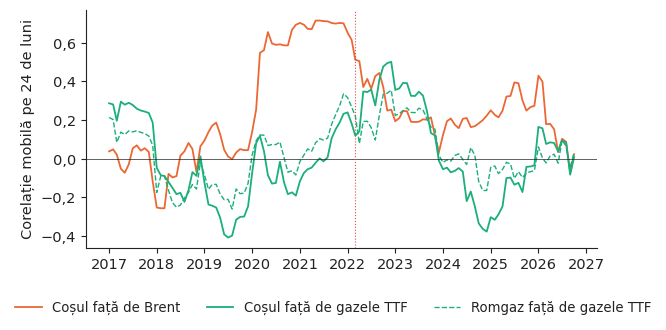

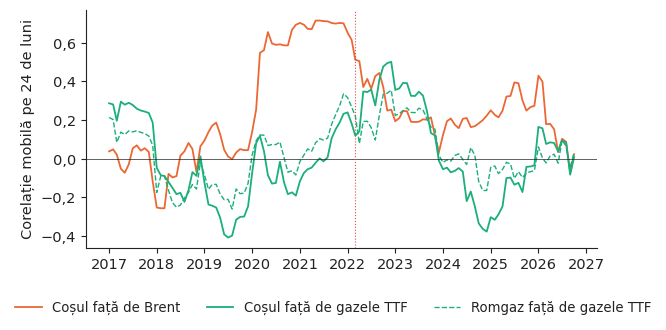

In [8]:
ttf = cu.ttf_monthly()["ttf_eur_mwh"]
mpx = px.resample("MS").last()
mr = 100 * np.log(pd.concat([mpx[["SNP", "SNG", "SNN", "Brent"]], ttf.rename("TTF")], axis=1).dropna()).diff().dropna()
mr["Basket"] = mr[["SNP", "SNG", "SNN"]].mean(axis=1)
roll = pd.DataFrame({"Brent": mr["Basket"].rolling(24).corr(mr["Brent"]), "TTF": mr["Basket"].rolling(24).corr(mr["TTF"]),
                     "SNG_TTF": mr["SNG"].rolling(24).corr(mr["TTF"])})
full_corr = mr[["Basket", "SNP", "SNG", "SNN"]].apply(lambda s: pd.Series({"Brent": s.corr(mr["Brent"]), "TTF": s.corr(mr["TTF"])}))
print(full_corr.round(3))
def fig_gas(lang):
    fig, ax = plt.subplots(figsize=(6.6, 3.1))
    ax.plot(roll.index, roll.Brent, color=cu.PAL["DE_LU"], label=cu.T(lang, "Basket vs Brent", "Coșul față de Brent"))
    ax.plot(roll.index, roll.TTF, color=cu.PAL["HU"], label=cu.T(lang, "Basket vs TTF gas", "Coșul față de gazele TTF"))
    ax.plot(roll.index, roll.SNG_TTF, color=cu.PAL["HU"], ls="--", lw=1.0, label=cu.T(lang, "Romgaz vs TTF gas", "Romgaz față de gazele TTF"))
    ax.axhline(0, color=cu.INK, lw=0.5); ax.axvline(pd.Timestamp("2022-02-24"), color=cu.EVENT, lw=0.8, ls=":")
    ax.set_ylabel(cu.T(lang, "24-month rolling correlation", "Corelație mobilă pe 24 de luni"))
    cu.comma_axis(ax, lang, "y", 1)
    cu.legend_bottom(fig, ncol=3)
    return fig
cu.save_both(fig_gas, "f3_gas_monthly")

## 5. Decizia: pot contractele futures pe Brent să acopere riscul unei poziții în acțiuni energetice românești?

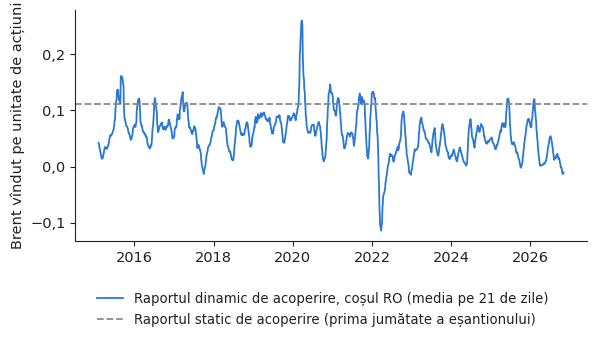

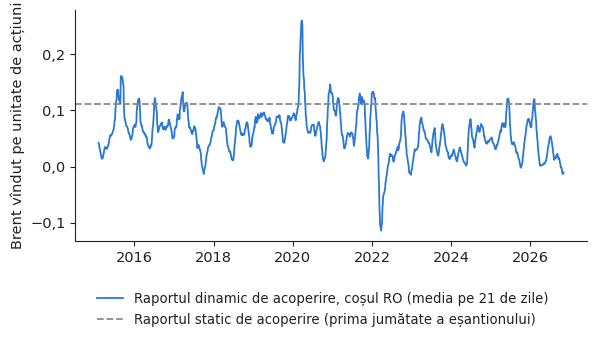

In [9]:
# Minimum-variance hedge: sell h units of Brent per unit of stock. Static h = cov/var on the first half; dynamic h_t = rho_t * sigma_s,t / sigma_b,t from DCC-GARCH.
# Out-of-sample discipline: the GARCH and DCC parameters (and Qbar) are estimated on the FIRST HALF only, then the second half is filtered
# with these fixed parameters (the full-sample fits above are descriptive and are not used for the hedge evaluation).
half = r.index[len(r) // 2]
ins, oos = r.loc[:half], r.loc[half:].iloc[1:]
std_o, vol_o = {}, {}
for c in ["SNP", "SNG", "SNN", "Basket", "Brent"]:
    fit_in = arch_model(r[c].loc[:half], mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
    fx = arch_model(r[c], mean="Constant", vol="GARCH", p=1, q=1, dist="t").fix(fit_in.params)    # filter the whole sample, parameters fixed
    std_o[c], vol_o[c] = fx.std_resid, fx.conditional_volatility                                  # sigma_t uses returns up to t-1
out = {}
for c in ["Basket", "SNP", "SNG", "SNN"]:
    h_static = ins[c].cov(ins["Brent"]) / ins["Brent"].var()
    z_all = pd.concat([std_o[c], std_o["Brent"]], axis=1)
    a_in, b_in, _, Qbar_in = dcc(z_all.loc[:half].values)                                          # DCC estimated on the first half
    rho_o = pd.Series(dcc_path(z_all.values, a_in, b_in, Qbar_in)[:, 0, 1], index=r.index)
    h_dyn = (rho_o * vol_o[c] / vol_o["Brent"]).loc[oos.index]   # rho_t, sigma_t are one-step forecasts made at t-1 (returns up to t-1 only)
    v0 = oos[c].var()
    out[c] = {"h_static": h_static, "h_dyn_mean": h_dyn.mean(),
              "eff_static": 100 * (1 - (oos[c] - h_static * oos["Brent"]).var() / v0),
              "eff_dyn": 100 * (1 - (oos[c] - h_dyn * oos["Brent"]).var() / v0)}
hedge = pd.DataFrame(out).T
cu.show_table(hedge, best={"eff_static": "max", "eff_dyn": "max"}, digits=3)
t = hedge.copy(); t.index = [names[i] for i in t.index]
cu.write_table(t, "hedge", header=[("Position", "Poziția"), ("Static $h$", "$h$ static"), ("Dynamic $h_t$, mean", "$h_t$ dinamic, media"),
                                   ("Variance cut, static, \\%", "Reducerea varianței, acoperire statică, \\%"), ("Variance cut, dynamic, \\%", "Reducerea varianței, acoperire dinamică, \\%")],
               digits={"h_static": 3, "h_dyn_mean": 3, "eff_static": 1, "eff_dyn": 1}, best={"eff_static": "max", "eff_dyn": "max"})
def fig_hedge(lang):
    fig, ax = plt.subplots(figsize=(6.6, 3.0))
    hd = (rho["Basket"] * vol_c["Basket"] / vol_c["Brent"])
    ax.plot(hd.index, hd.rolling(21).mean(), color=cu.PAL["RO"], label=cu.T(lang, "Dynamic hedge ratio, basket (21-day mean)", "Raportul dinamic de acoperire, coșul RO (media pe 21 de zile)"))
    ax.axhline(hedge.loc["Basket", "h_static"], color=cu.MUTED, ls="--", label=cu.T(lang, "Static hedge ratio (first half)", "Raportul static de acoperire (prima jumătate a eșantionului)"))
    ax.set_ylabel(cu.T(lang, "Brent sold per unit of stock", "Brent vîndut pe unitate de acțiuni"))
    cu.comma_axis(ax, lang, "y", 2)
    cu.legend_bottom(fig, ncol=1)
    return fig
cu.save_both(fig_hedge, "f4_hedge_ratio")

In [10]:
b = summary.loc["Basket"]
cu.write_numbers({
    "start": (f"{r.index.min():%d %B %Y}", f"{r.index.min():%d.%m.%Y}"), "end": (f"{r.index.max():%d %B %Y}", f"{r.index.max():%d.%m.%Y}"),
    "nObs": len(r), "dccA": dcc_par["Basket"][0], "dccB": dcc_par["Basket"][1],
    "rhoMean": b["mean"], "rhoMax": b["max"], "rhoMaxYear": int(b["year_max"]), "rhoMin": b["min"], "rhoMinYear": int(b["year_min"]),
    "snpMean": summary.loc["SNP", "mean"], "sngMean": summary.loc["SNG", "mean"], "snnMean": summary.loc["SNN", "mean"],
    "msHigh": b["const_high"], "msLow": b["const_low"], "pHH": b["p_stay_high"], "pLL": b["p_stay_low"], "shareHigh": ms["Basket"]["share_high"],
    "ttfCorr": full_corr.loc["TTF", "Basket"], "brentCorrM": full_corr.loc["Brent", "Basket"], "sngTTF": full_corr.loc["TTF", "SNG"],
    "hStatic": hedge.loc["Basket", "h_static"], "effStatic": hedge.loc["Basket", "eff_static"], "effDyn": hedge.loc["Basket", "eff_dyn"],
    "effSNP": hedge.loc["SNP", "eff_dyn"], "nOOS": len(oos), "half": (f"{half:%B %Y}", f"{half:%m.%Y}"),
}, digits={"dccA": 4, "dccB": 4, "pHH": 4, "pLL": 4, "msHigh": 3, "msLow": 3, "shareHigh": 1, "hStatic": 3, "effStatic": 1, "effDyn": 1, "effSNP": 1,
           "ttfCorr": 2, "brentCorrM": 2, "sngTTF": 2})

In [11]:
# slide-ready summary for the lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
for lang in ("en", "ro"):
    F = lambda v, nd=2: cu.fmt(float(v), nd, lang).replace("-", "$-$")
    t = lambda en, ro: ro if lang == "ro" else en
    lines = [
        t("\\textbf{Energy prices and EU stock markets} (Grecu, Cramer, Pele \\& Lessmann, 2025, NAJEF): DCC-GARCH + Markov switching; CEE index least correlated with oil (max 0.53 in 2020, min $-$0.11 in 2022, Table~2); regimes persist $>$98\\,\\% (Table~4).",
          "\\textbf{Prețurile energiei și bursele din UE} (Grecu, Cramer, Pele și Lessmann, 2025, NAJEF): DCC-GARCH și modele Markov; indicele ECE este cel mai slab corelat cu petrolul (max 0,53 în 2020, min $-$0,11 în 2022, Tabelul~2); probabilitatea de persistență a regimurilor depășește 98\\,\\% (Tabelul~4)."),
        t(f"Our data (SNP, SNG, SNN vs Brent, {r.index.min().year}--{r.index.max().year}): mean correlation {F(b['mean'])}, max {F(b['max'])} ({int(b['year_max'])}), min {F(b['min'])} ({int(b['year_min'])}) --- the same calendar.",
          f"Datele cursului (SNP, SNG, SNN față de Brent, {r.index.min().year}--{r.index.max().year}): corelația medie {F(b['mean'])}, max {F(b['max'])} ({int(b['year_max'])}), min {F(b['min'])} ({int(b['year_min'])}) --- aceeași cronologie."),
        t(f"Decision: out of sample (after {half:%B %Y}), the variance cut of a Romanian energy-share basket hedged with Brent is {F(hedge.loc['Basket', 'eff_dyn'], 1)}\\,\\% (dynamic hedge) and {F(hedge.loc['Basket', 'eff_static'], 1)}\\,\\% (static; negative = more risk) --- their risk is regulatory and local, not oil.",
          f"Decizia: în afara eșantionului de estimare (după {half:%m.%Y}), reducerea varianței unui coș de acțiuni energetice românești acoperit cu Brent este de {F(hedge.loc['Basket', 'eff_dyn'], 1)}\\,\\% (acoperire dinamică) și de {F(hedge.loc['Basket', 'eff_static'], 1)}\\,\\% (statică; o valoare negativă înseamnă risc mai mare) --- riscul acestora este de reglementare și de piață locală, nu legat de petrol."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Energy prices and EU stock markets} (Grecu, Cramer, Pele \& Lessmann, 2025, NAJEF): DCC-GARCH + Markov switching; CEE index least correlated with oil (max 0.53 in 2020, min $-$0.11 in 2022, Table~2); regimes persist $>$98\,\% (Table~4).
  \item Our data (SNP, SNG, SNN vs Brent, 2015--2026): mean correlation 0.13, max 0.54 (2020), min $-$0.32 (2022) --- the same calendar.
  \item Decision: out of sample (after December 2020), the variance cut of a Romanian energy-share basket hedged with Brent is $-$1.7\,\% (dynamic hedge) and $-$6.9\,\% (static; negative = more risk) --- their risk is regulatory and local, not oil.
\end{itemize}



## Exerciții suplimentare
1. Adăugați Hidroelectrica (H2O, listată în iulie 2023). Este un producător de energie hidro legat în vreun fel de prețul petrolului? Argumentați.
2. Reestimați modelul Markov numai pe corelația SNG–Brent. Își schimbă Romgaz regimul la aceleași date ca Petrom?
3. Lucrarea arată că țările cele mai industrializate reacționează mai puternic la șocurile prețului petrolului. Care dintre companiile listate în România v-ați aștepta să fie cele mai expuse?